# 05. Multiclass Image Classification on CIFAR-10

Welcome to the 5th notebook in the [DeepLearning_with_PyTorch](https://github.com/ShivaUlavi/DeepLearning_with_PyTorch) series!

In the previous notebook (**04_Going_Deeper_with_convolutions**), we explored custom CNN architectures designed specifically for binary classification (distinguishing only between *birds* and *planes*). In this project, we scale our modeling up to solve the full **10-class multiclass classification task** using the complete CIFAR-10 dataset.

We design, train, and evaluate three progressively powerful PyTorch architectures:
1. **Standard ConvNet** (Base architecture with ~18% validation accuracy)
2. **Improved CNN** (Deep blocks with Batch Normalization and Dropout achieving ~69% accuracy)
3. **ResNet-18 Adapted for CIFAR** (Residual Skip Connections achieving **81.8%** accuracy)

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import torch.nn.functional as f
import numpy as np


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


## 1. Hyperparameters & Data Preparation

We set our baseline hyperparameters and construct data pipelines using `torchvision.transforms` to convert images to tensors and normalize their values.

In [ ]:
#hyper parameters
num_epoch = 25
batch_size = 128
learning_rate = 0.001

#dataset has PIL images of range [0,1] and normalize the tensors to be in the range [-1,1]
transform = transforms.Compose([transforms.ToTensor(),
                              transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5 ))])

In [ ]:
train_dataset = torchvision.datasets.CIFAR10(root = '../data-unversioned/CIFAR/', train=True, transform=transform)

test_dataset = torchvision.datasets.CIFAR10(root = '../data-unversioned/CIFAR/', train=False, transform=transform)

# Added num_workers and pin_memory=True
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

## 2. Visualizing CIFAR-10 Samples

Let's plot a batch of images from our training loader to verify the dataset loader and normalization.

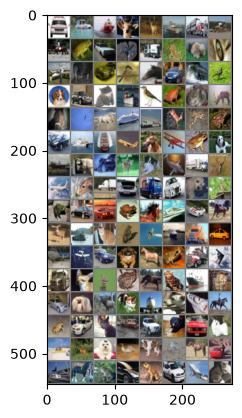

In [ ]:
def imshow(img):
    img = img / 2 + 0.5  # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(train_loader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))

## 3. Model 1: Baseline ConvNet Architecture

A basic, classic CNN structure consisting of convolution layers, max pooling, and fully connected linear layers.

In [ ]:
##defining our model
class ConvNet(nn.Module):
    def __init__(self):
        super(ConvNet, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2,2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84,10)

    def forward(self, x):
        out = self.pool(f.relu(self.conv1(x)))
        out = self.pool(f.relu(self.conv2(out)))
        out = out.view(-1, 16 * 5 * 5)
        out = f.relu(self.fc1(out))
        out = f.relu(self.fc2(out))
        out = self.fc3(out)
        return out

In [ ]:
model = ConvNet().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

n_total_steps = len(train_loader)
for epoch in range(num_epoch):
    for i, (images, labels) in enumerate(train_loader):
        # origin shape: [128, 3, 32, 32] = 4, 3, 1024
        # input_layer: 3 input channels, 6 output channels, 5 kernel size
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (i+1) % 2000 == 0:
            print (f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

print('Finished Training')
PATH = './cnn.pth'
torch.save(model.state_dict(), PATH)

Finished Training


In [ ]:
with torch.no_grad():
    n_correct = 0
    n_samples = 0
    n_class_correct = [0 for i in range(10)]
    n_class_samples = [0 for i in range(10)]
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        # max returns (value ,index)
        _, predicted = torch.max(outputs, 1)
        n_samples += labels.size(0)
        n_correct += (predicted == labels).sum().item()

        for i in range(labels.size(0)):
            label = labels[i].item()
            pred = predicted[i].item()
            if (label == pred):
                n_class_correct[label] += 1
            n_class_samples[label] += 1


    acc = 100.0 * n_correct / n_samples
    print(f'Accuracy of the network: {acc} %')

Accuracy of the network: 17.96 %


In [ ]:
for i in range(10):
    acc = 100.0 * n_class_correct[i] / n_class_samples[i]
    print(f'Accuracy of {classes[i]}: {acc} %')

Accuracy of plane: 45.1 %
Accuracy of car: 53.5 %
Accuracy of bird: 0.0 %
Accuracy of cat: 0.0 %
Accuracy of deer: 0.0 %
Accuracy of dog: 0.0 %
Accuracy of frog: 0.0 %
Accuracy of horse: 30.8 %
Accuracy of ship: 8.0 %
Accuracy of truck: 42.2 %


## 4. Model 2: Improved CNN Architecture

To improve on our baseline, we introduce a deeper block-based network with **Batch Normalization** to stabilize training and **Dropout** to prevent overfitting.

A complex and improved ConvNet

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ImprovedCNN(nn.Module):
    def __init__(self):
        super(ImprovedCNN, self).__init__()

        # Block 1 (Input: 3 x 32 x 32)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool1 = nn.MaxPool2d(2, 2) # Reduces to 64 x 16 x 16

        # Block 2
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(2, 2) # Reduces to 128 x 8 x 8

        # Fully Connected Layers
        self.fc1 = nn.Linear(128 * 8 * 8, 512)
        self.dropout = nn.Dropout(0.5) # Prevents overfitting
        self.fc2 = nn.Linear(512, 10)  # Output layer for 10 classes

    def forward(self, x):
        # Block 1 forward
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool1(F.relu(self.bn2(self.conv2(x))))

        # Block 2 forward
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool2(F.relu(self.bn4(self.conv4(x))))

        # Flatten for linear layers
        x = x.view(-1, 128 * 8 * 8)

        # Classifier forward
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


In [ ]:
model = ImprovedCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

n_total_steps = len(train_loader)
for epoch in range(num_epoch):
    for i, (images, labels) in enumerate(train_loader):
        # origin shape: [128, 3, 32, 32] = 4, 3, 1024
        # input_layer: 3 input channels, 6 output channels, 5 kernel size
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (i+1) % 100 == 0:
            print (f'Epoch [{epoch+1}/{num_epoch}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

print('Finished Training')
PATH = './cnn.pth'
torch.save(model.state_dict(), PATH)

Epoch [1/25], Step [100/391], Loss: 2.1051
Epoch [1/25], Step [200/391], Loss: 1.9982
Epoch [1/25], Step [300/391], Loss: 1.8456
Epoch [2/25], Step [100/391], Loss: 1.6255
Epoch [2/25], Step [200/391], Loss: 1.6482
Epoch [2/25], Step [300/391], Loss: 1.5614
Epoch [3/25], Step [100/391], Loss: 1.5531
Epoch [3/25], Step [200/391], Loss: 1.5111
Epoch [3/25], Step [300/391], Loss: 1.3748
Epoch [4/25], Step [100/391], Loss: 1.4472
Epoch [4/25], Step [200/391], Loss: 1.3422
Epoch [4/25], Step [300/391], Loss: 1.2999
Epoch [5/25], Step [100/391], Loss: 1.2970
Epoch [5/25], Step [200/391], Loss: 1.4391
Epoch [5/25], Step [300/391], Loss: 1.3546
Epoch [6/25], Step [100/391], Loss: 1.4885
Epoch [6/25], Step [200/391], Loss: 1.2590
Epoch [6/25], Step [300/391], Loss: 1.3505
Epoch [7/25], Step [100/391], Loss: 1.4322
Epoch [7/25], Step [200/391], Loss: 1.4363
Epoch [7/25], Step [300/391], Loss: 1.1785
Epoch [8/25], Step [100/391], Loss: 1.1466
Epoch [8/25], Step [200/391], Loss: 1.2181
Epoch [8/25

In [ ]:
with torch.no_grad():
    n_correct = 0
    n_samples = 0
    n_class_correct = [0 for i in range(10)]
    n_class_samples = [0 for i in range(10)]
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        # max returns (value ,index)
        _, predicted = torch.max(outputs, 1)
        n_samples += labels.size(0)
        n_correct += (predicted == labels).sum().item()

        for i in range(labels.size(0)):
            label = labels[i].item()
            pred = predicted[i].item()
            if (label == pred):
                n_class_correct[label] += 1
            n_class_samples[label] += 1


    acc = 100.0 * n_correct / n_samples
    print(f'Accuracy of the network: {acc} %')

Accuracy of the network: 68.89 %


In [ ]:
for i in range(10):
    acc = 100.0 * n_class_correct[i] / n_class_samples[i]
    print(f'Accuracy of {classes[i]}: {acc} %')

Accuracy of plane: 73.0 %
Accuracy of car: 82.4 %
Accuracy of bird: 54.1 %
Accuracy of cat: 50.9 %
Accuracy of deer: 60.8 %
Accuracy of dog: 59.1 %
Accuracy of frog: 79.5 %
Accuracy of horse: 74.6 %
Accuracy of ship: 77.6 %
Accuracy of truck: 76.9 %


## 5. Model 3: Adapted ResNet-18 for CIFAR-10

Finally, we adapt the industry-standard **ResNet-18** architecture. Rather than using aggressive downsampling (which is typical for large $224 \times 224$ ImageNet images), we adapt the first convolutional block with a $3 \times 3$ kernel, stride 1, and no pooling to retain spatial details of smaller $32 \times 32$ CIFAR images.

### ResNeT-18 CIFAR Adapted

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, self.expansion * planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(self.expansion * planes)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = F.relu(out)
        return out


class ResNet18CIFAR(nn.Module):
    def __init__(self, block=BasicBlock, num_blocks=[2, 2, 2, 2], num_classes=10):
        super(ResNet18CIFAR, self).__init__()
        self.in_planes = 64

        # Modified initial layer for 32x32 CIFAR images (no aggressive 7x7 stride-2 conv)
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)

        self.layer1 = self._make_layer(block, 64, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 128, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 256, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(block, 512, num_blocks[3], stride=2)

        self.linear = nn.Linear(512 * block.expansion, num_classes)

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_planes, planes, stride))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)  # <-- Wrap the list in nn.Sequential

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = F.avg_pool2d(out, 4)
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out

In [ ]:
model = ResNet18CIFAR().to(device)

import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)

n_total_steps = len(train_loader)
for epoch in range(num_epoch):
    for i, (images, labels) in enumerate(train_loader):
        # origin shape: [128, 3, 32, 32] = 4, 3, 1024
        # input_layer: 3 input channels, 6 output channels, 5 kernel size
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (i+1) % 100 == 0:
            print (f'Epoch [{epoch+1}/{num_epoch}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

print('Finished Training')
PATH = './cnn.pth'
torch.save(model.state_dict(), PATH)

Epoch [1/25], Step [100/391], Loss: 1.9671
Epoch [1/25], Step [200/391], Loss: 1.6246
Epoch [1/25], Step [300/391], Loss: 1.5028
Epoch [2/25], Step [100/391], Loss: 1.2462
Epoch [2/25], Step [200/391], Loss: 1.2789
Epoch [2/25], Step [300/391], Loss: 1.0718
Epoch [3/25], Step [100/391], Loss: 0.8811
Epoch [3/25], Step [200/391], Loss: 0.6668
Epoch [3/25], Step [300/391], Loss: 0.8130
Epoch [4/25], Step [100/391], Loss: 0.7968
Epoch [4/25], Step [200/391], Loss: 0.7623
Epoch [4/25], Step [300/391], Loss: 0.7137
Epoch [5/25], Step [100/391], Loss: 0.5056
Epoch [5/25], Step [200/391], Loss: 0.5748
Epoch [5/25], Step [300/391], Loss: 0.5378
Epoch [6/25], Step [100/391], Loss: 0.4246
Epoch [6/25], Step [200/391], Loss: 0.5311
Epoch [6/25], Step [300/391], Loss: 0.5385
Epoch [7/25], Step [100/391], Loss: 0.3435
Epoch [7/25], Step [200/391], Loss: 0.3254
Epoch [7/25], Step [300/391], Loss: 0.5623
Epoch [8/25], Step [100/391], Loss: 0.2483
Epoch [8/25], Step [200/391], Loss: 0.4297
Epoch [8/25

In [ ]:
with torch.no_grad():
    n_correct = 0
    n_samples = 0
    n_class_correct = [0 for i in range(10)]
    n_class_samples = [0 for i in range(10)]
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        # max returns (value ,index)
        _, predicted = torch.max(outputs, 1)
        n_samples += labels.size(0)
        n_correct += (predicted == labels).sum().item()

        for i in range(labels.size(0)):
            label = labels[i].item()
            pred = predicted[i].item()
            if (label == pred):
                n_class_correct[label] += 1
            n_class_samples[label] += 1


    acc = 100.0 * n_correct / n_samples
    print(f'Accuracy of the network: {acc} %')

Accuracy of the network: 81.8 %


In [ ]:
for i in range(10):
    acc = 100.0 * n_class_correct[i] / n_class_samples[i]
    print(f'Accuracy of {classes[i]}: {acc} %')

Accuracy of plane: 80.4 %
Accuracy of car: 90.2 %
Accuracy of bird: 75.5 %
Accuracy of cat: 53.0 %
Accuracy of deer: 79.5 %
Accuracy of dog: 81.7 %
Accuracy of frog: 88.1 %
Accuracy of horse: 85.3 %
Accuracy of ship: 91.8 %
Accuracy of truck: 92.5 %


## 6. Project Summary & Comparative Analysis

### Performance Highlights

| Model Architecture | Accuracy (%) | Key Design Implementations |
| :--- | :--- | :--- |
| **Baseline ConvNet** | **17.96%** | Basic 2-layer convolution, no normalization, SGD optimizer with lr=0.001 |
| **Improved CNN** | **68.89%** | 4-layer convolution blocks, Batch Normalization, Dropout (0.5), FC layers |
| **ResNet-18 (CIFAR)** | **81.80%** | Residual/skip connections, 18-layer deep architecture, modified input stem |

### Core Insights
- **Importance of Normalization**: Introducing `BatchNorm2d` after convolutional blocks helped deep layers converge efficiently and vastly boosted accuracy.
- **Residual Connections**: Skip connections enabled us to train an 18-layer architecture without suffering from the vanishing gradient problem, achieving a spectacular **81.8%** final accuracy.
- **Handling Small Images**: Customizing ResNet's initial convolution layer to preserve spatial structure ($3 \times 3$ stride 1 instead of standard $7 \times 7$ stride 2) is crucial for success on low-resolution datasets like CIFAR-10.

***

*This notebook is part of the [DeepLearning_with_PyTorch](https://github.com/ShivaUlavi/DeepLearning_with_PyTorch) repository. Check out the previous notebook on binary classification (`04_Going_Deeper_with_convolutions`) to compare binary vs. multiclass strategies!*